## Data preparation

* Check if the missing values are presented in the features.
* If there are missing values:
    * For categorical features, replace them with 'NA'
    * For numerical features, replace with with 0.0 


Split the data into 3 parts with these exact calls:

```python
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)
```

### In this dataset our desired target for classification task will be converted variable - has the client signed up to the platform or not.

In [10]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

In [11]:
from sklearn.model_selection import train_test_split,KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import auc, roc_curve, accuracy_score, roc_auc_score

In [81]:
!pip install tqdm

In [82]:
from tqdm.auto import tqdm

In [12]:
data = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv'
!wget $data -O data-week-4.csv 

--2026-10-18 11:13:28--  https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.109.133, 185.199.110.133, 185.199.108.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.109.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 278746 (272K) [text/plain]
Saving to: ‘data-week-4.csv’

data-week-4.csv     100%[===================>] 272.21K  --.-KB/s    in 0.01s   

2026-10-18 11:13:28 (18.7 MB/s) - ‘data-week-4.csv’ saved [278746/278746]



In [39]:
df = pd.read_csv('data-week-4.csv')

In [40]:
categorical_columns = list(df.dtypes[df.dtypes == 'object'].index)
numerical_columns = [
    c for c in df.select_dtypes(include=['number']).columns 
    if c != 'converted'
]

In [41]:
df.columns = df.columns.str.lower().str.replace(' ', '_')

for c in categorical_columns:
    df[c] = df[c].str.lower().str.replace(' ', '_')
    df[c] = df[c].fillna('NA')

df[numerical_columns] = df[numerical_columns].fillna(0)

In [45]:
categorical = categorical_columns
numerical = numerical_columns

In [46]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values

del df_train['converted']
del df_val['converted']
del df_test['converted']

In [47]:
dv = DictVectorizer(sparse=False)

train_dict = df_train[categorical + numerical].to_dict(orient='records')
X_train = dv.fit_transform(train_dict)

model = LogisticRegression()
model.fit(X_train, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression()

In [48]:
val_dict = df_val[categorical + numerical].to_dict(orient='records')
X_val = dv.transform(val_dict)

y_pred = model.predict_proba(X_val)[:, 1]
converted_decision = (y_pred >= 0.5)
(y_val == converted_decision).mean()

np.float64(0.722)

### Confusion table

In [55]:
actual_positive = (y_val == 1)
actual_negative = (y_val == 0)

t = 0.5
predict_positive = (y_pred >= t)
predict_negative = (y_pred < t)

tp = (predict_positive & actual_positive).sum()
tn = (predict_negative & actual_negative).sum()

fp = (predict_positive & actual_negative).sum()
fn = (predict_negative & actual_positive).sum()

In [58]:
tpr = tp / (tp + fn)
fpr = fp / (fp + tn)

print(f'tpr : {tpr} , fpr : {fpr}')

tpr : 0.8174061433447098 , fpr : 0.41304347826086957


## Question 1: ROC AUC feature importance

ROC AUC could also be used to evaluate feature importance of numerical variables. 

Let's do that

* For each numerical variable, use it as score (aka prediction) and compute the AUC with the `y` variable as ground truth.
* Use the training dataset for that


If your AUC is < 0.5, invert this variable by putting "-" in front

(e.g. `-df_train['balance']`)

AUC can go below 0.5 if the variable is negatively correlated with the target variable. You can change the direction of the correlation by negating this variable - then negative correlation becomes positive.

Which numerical variable (among the following 4) has the highest AUC?

- `lead_score`
- `number_of_courses_viewed`
- `interaction_count`
- `annual_income`

In [64]:
numerical_cols = ['lead_score', 'number_of_courses_viewed', 'interaction_count', 'annual_income']

auc_results = {}

for col in numerical_cols:
    scores = df_train[col].values
    auc = roc_auc_score(y_train, scores)
    
    if auc < 0.5:
        auc = roc_auc_score(y_train, -scores)
        
    auc_results[col] = auc
    print(f'{col}: {auc:.4f}')

best_feature = max(auc_results, key=auc_results.get)
print(f"\nFeature ที่มีค่า AUC สูงที่สุดคือ: {best_feature} (AUC = {auc_results[best_feature]:.4f})")

lead_score: 0.7882
number_of_courses_viewed: 0.7230
interaction_count: 0.7649
annual_income: 0.6082

Feature ที่มีค่า AUC สูงที่สุดคือ: lead_score (AUC = 0.7882)


## Question 2: Training the model

Apply one-hot-encoding using `DictVectorizer` and train the logistic regression with these parameters:

```python
LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
```

What's the AUC of this model on the validation dataset? (round to 3 digits)

- 0.532
- 0.632
- 0.732
- 0.832

In [73]:
train_dicts = df_train[categorical + numerical].to_dict(orient='records')
val_dicts = df_val[categorical + numerical].to_dict(orient='records')
dv = DictVectorizer(sparse=False)

X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)

model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)

y_pred = model.predict_proba(X_val)[:, 1]
auc = roc_auc_score(y_val, y_pred)

print(f"Validation AUC: {round(auc, 3)}")

Validation AUC: 0.732


## Question 3: Precision and Recall

Now let's compute precision and recall for our model.

* Evaluate the model on all thresholds from 0.0 to 1.0 with step 0.01
* For each threshold, compute precision and recall
* Plot them

At which threshold precision and recall curves intersect? Ignore thresholds at
which both metrics are zero, and choose the threshold with the smallest
absolute difference between precision and recall.

* 0.43
* 0.63
* 0.73
* 0.83

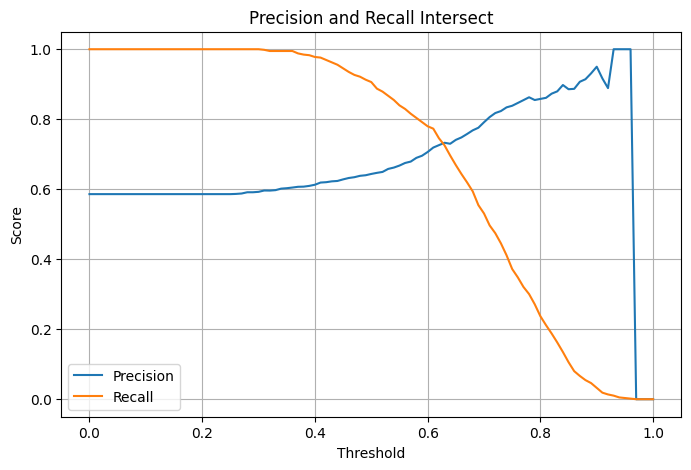

Intersection Threshold (Smallest absolute difference): 0.63


In [78]:
thresholds = np.linspace(0.0, 1.0, 101)

scores = []

for t in thresholds:
    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)
    
    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)
    
    tp = (predict_positive & actual_positive).sum()
    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()
    
    p = tp / (tp + fp) if (tp + fp) > 0 else 0
    r = tp / (tp + fn) if (tp + fn) > 0 else 0
    
    scores.append({
        'threshold': t,
        'precision': p,
        'recall': r,
        'diff': abs(p - r)
    })

df_scores = pd.DataFrame(scores)

plt.figure(figsize=(8, 5))
plt.plot(df_scores.threshold, df_scores.precision, label='Precision')
plt.plot(df_scores.threshold, df_scores.recall, label='Recall')
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.title('Precision and Recall Intersect')
plt.legend()
plt.grid(True)
plt.show()

df_filtered = df_scores[(df_scores.precision > 0) & (df_scores.recall > 0)]
best_threshold = df_filtered.loc[df_filtered['diff'].idxmin()]['threshold']

print(f"Intersection Threshold (Smallest absolute difference): {best_threshold:.2f}")

## Question 4: F1 score

Precision and recall are conflicting - when one grows, the other goes down. That's why they are often combined into the F1 score - a metrics that takes into account both

This is the formula for computing F1:

$$F_1 = 2 \cdot \cfrac{P \cdot R}{P + R}$$

Where $P$ is precision and $R$ is recall.

Let's compute F1 for all thresholds from 0.0 to 1.0 with increment 0.01

At which threshold F1 is maximal?

- 0.21
- 0.41
- 0.61
- 0.81


Best Threshold for F1-Score: 0.41
Max F1-Score: 0.7576


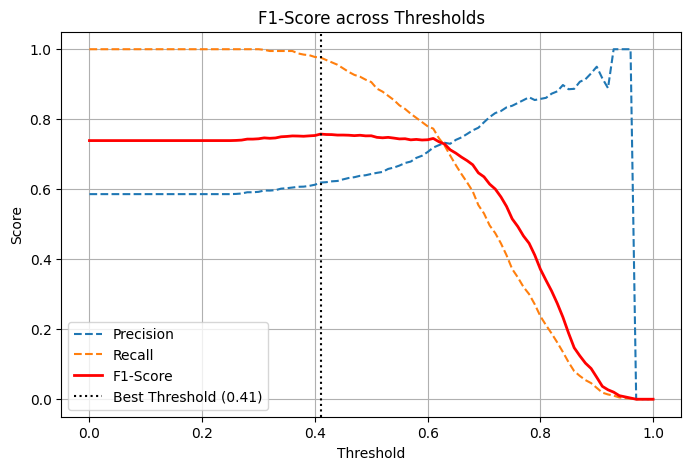

In [79]:
thresholds = np.linspace(0.0, 1.0, 101)
scores = []

for t in thresholds:
    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)
    
    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)
    
    tp = (predict_positive & actual_positive).sum()
    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()
    
    p = tp / (tp + fp) if (tp + fp) > 0 else 0
    r = tp / (tp + fn) if (tp + fn) > 0 else 0
    
    f1 = 2 * (p * r) / (p + r) if (p + r) > 0 else 0
    
    scores.append({
        'threshold': t,
        'precision': p,
        'recall': r,
        'f1': f1
    })

df_scores = pd.DataFrame(scores)

best_row = df_scores.loc[df_scores['f1'].idxmax()]
best_threshold = best_row['threshold']
max_f1 = best_row['f1']

print(f"Best Threshold for F1-Score: {best_threshold:.2f}")
print(f"Max F1-Score: {max_f1:.4f}")

plt.figure(figsize=(8, 5))
plt.plot(df_scores.threshold, df_scores.precision, label='Precision', linestyle='--')
plt.plot(df_scores.threshold, df_scores.recall, label='Recall', linestyle='--')
plt.plot(df_scores.threshold, df_scores.f1, label='F1-Score', color='red', linewidth=2)

plt.axvline(x=best_threshold, color='black', linestyle=':', label=f'Best Threshold ({best_threshold:.2f})')
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.title('F1-Score across Thresholds')
plt.legend()
plt.grid(True)
plt.show()

## Question 5: 5-Fold CV

Use the `KFold` class from Scikit-Learn to evaluate our model on 5 different folds:

```
KFold(n_splits=5, shuffle=True, random_state=1)
```

* Iterate over different folds of `df_full_train`
* Split the data into train and validation
* Train the model on train with these parameters: `LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)`
* Use AUC to evaluate the model on validation

How large is standard deviation of the scores across different folds?

- 0.001
- 0.007
- 0.013
- 0.060

In [83]:
n_splits = 5

for C in tqdm([0.001, 0.01, 0.1, 0.5, 1, 5, 10]):
    kfold = KFold(n_splits=n_splits, shuffle=True, random_state=1)

    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]

        y_train = df_train.converted.values
        y_val = df_val.converted.values

        dv, model = train(df_train, y_train, C=C)
        y_pred = predict(df_val, dv, model)

        auc = roc_auc_score(y_val, y_pred)
        scores.append(auc)

    print('C=%s %.3f +- %.3f' % (C, np.mean(scores), np.std(scores)))

  0%|          | 0/7 [00:00<?, ?it/s]

C=0.001 0.749 +- 0.010
C=0.01 0.733 +- 0.007
C=0.1 0.732 +- 0.007
C=0.5 0.732 +- 0.007
C=1 0.732 +- 0.007
C=5 0.732 +- 0.007
C=10 0.732 +- 0.007


## Question 6: Hyperparameter Tuning

Now let's use 5-Fold cross-validation to find the best parameter `C`

* Iterate over the following `C` values: `[0.000001, 0.001, 1]`
* Initialize `KFold` with the same parameters as previously
* Use these parameters for the model: `LogisticRegression(solver='liblinear', C=C, max_iter=1000)`
* Compute the mean ROC AUC as well as the std (round the mean and std to 3
  decimal digits).

Which `C` leads to the best mean ROC AUC?

- 0.000001
- 0.001
- 1

If you have ties, select the score with the lowest std. If you still have ties, select the smallest `C`.

In [86]:
c_values = [0.000001, 0.001, 1]

kfold = KFold(n_splits=5, shuffle=True, random_state=1)

features = categorical + numerical 

results = []

for C in c_values:
    scores = []
    
    for train_idx, val_idx in kfold.split(df_full_train):
        df_train_fold = df_full_train.iloc[train_idx]
        df_val_fold = df_full_train.iloc[val_idx]
        
        y_train_fold = df_train_fold.converted.values 
        y_val_fold = df_val_fold.converted.values
        
        # One-Hot Encoding ด้วย DictVectorizer
        train_dicts = df_train_fold[features].to_dict(orient='records')
        val_dicts = df_val_fold[features].to_dict(orient='records')
        
        dv = DictVectorizer(sparse=False)
        X_train_fold = dv.fit_transform(train_dicts)
        X_val_fold = dv.transform(val_dicts)
        
        # Train Model
        model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
        model.fit(X_train_fold, y_train_fold)
        
        # Predict & Evaluate
        y_pred = model.predict_proba(X_val_fold)[:, 1]
        auc = roc_auc_score(y_val_fold, y_pred)
        scores.append(auc)
        
    mean_auc = round(np.mean(scores), 3)
    std_auc = round(np.std(scores), 3)
    
    results.append({
        'C': C,
        'mean_auc': mean_auc,
        'std_auc': std_auc
    })
    print(f'C={C:<8} | Mean AUC: {mean_auc:.3f} +- {std_auc:.3f}')

df_results = pd.DataFrame(results)

C=1e-06    | Mean AUC: 0.617 +- 0.019
C=0.001    | Mean AUC: 0.749 +- 0.010
C=1        | Mean AUC: 0.732 +- 0.007
